# Практична робота 4.8
## Регресія та класифікація з використанням TensorFlow / Keras

**Варіант: номер за журналом N = 5**
- кількість даних: `1000 × N = 5000`;
- кількість класів у задачі класифікації: `N + 2 = 7`.

**План роботи**
1. Генерація даних (`make_regression`, `make_classification`) та їх візуалізація.
2. Побудова та навчання нейронних мереж для регресії та класифікації (TensorFlow/Keras).
3. Оцінка: MSE для регресії; Accuracy та матриця плутанини для класифікації.
4. Висновки.

## 0. Параметри варіанта та імпорт бібліотек

In [1]:
# %pip install tensorflow scikit-learn matplotlib seaborn pandas   # за потреби

N = 5                       # номер за журналом
N_SAMPLES = 1000 * N        # 5000
N_CLASSES = N + 2           # 7
RANDOM_STATE = 42

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import make_regression, make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)
keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| N =", N, "| зразків:", N_SAMPLES, "| класів:", N_CLASSES)

TensorFlow 2.21.0 | N = 5 | зразків: 5000 | класів: 7


## 1. Генерація даних
### 1.1. Дані для регресії
`make_regression` створює ознаки з нормального розподілу і цільову змінну як лінійну комбінацію інформативних ознак + гаусів шум. Щоб задача була цікавішою для нейронної мережі, додамо **нелінійну складову** (квадрат і синус ознак) — лінійна модель її не вловить, а нейромережа зможе.

In [2]:
X_reg, y_lin = make_regression(n_samples=N_SAMPLES, n_features=6, n_informative=4,
                               noise=10, random_state=RANDOM_STATE)
y_reg = y_lin + 25 * X_reg[:, 0] ** 2 + 40 * np.sin(2 * X_reg[:, 1])   # нелінійність

print("X_reg:", X_reg.shape, " y_reg:", y_reg.shape)
pd.DataFrame(X_reg, columns=[f"x{i}" for i in range(X_reg.shape[1])]).assign(y=y_reg).describe().round(2)

X_reg: (5000, 6)  y_reg: (5000,)


,x0,x1,x2,x3,x4,x5,y
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,-0.01,0.00,0.01,0.00,-0.00,-0.00,23.88
std,0.99,0.99,1.01,1.02,0.99,1.00,142.00
min,-3.69,-3.50,-3.84,-3.86,-3.33,-3.92,-398.88
25%,-0.69,-0.65,-0.68,-0.69,-0.69,-0.67,-72.09
50%,-0.01,0.00,0.01,-0.00,0.00,0.01,20.88
75%,0.64,0.66,0.69,0.70,0.67,0.67,116.68
max,4.48,3.94,3.69,3.28,3.43,3.61,657.05


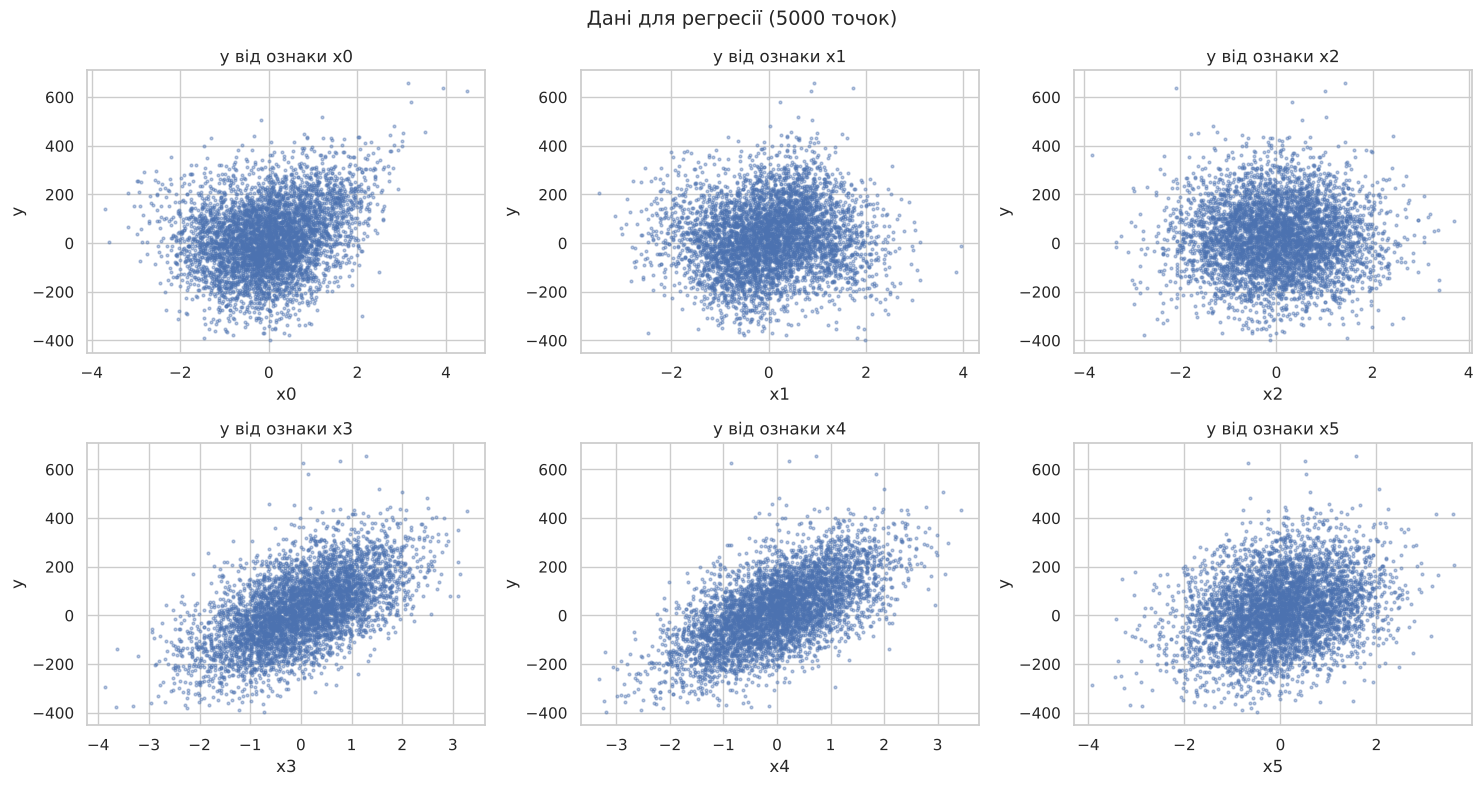

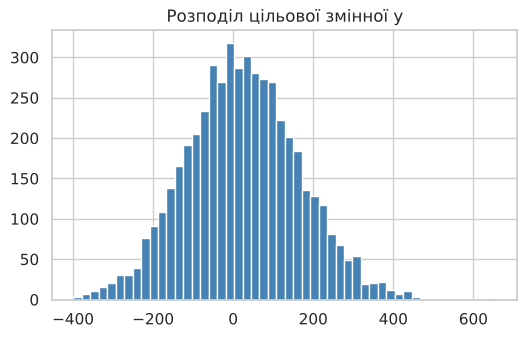

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, ax in enumerate(axes.flat):
    ax.scatter(X_reg[:, i], y_reg, s=4, alpha=0.4)
    ax.set_xlabel(f"x{i}"); ax.set_ylabel("y")
    ax.set_title(f"y від ознаки x{i}")
plt.suptitle("Дані для регресії (5000 точок)", fontsize=14)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.5))
plt.hist(y_reg, bins=50, color="steelblue")
plt.title("Розподіл цільової змінної y"); plt.show()

На графіках видно лінійні залежності `y` від частини ознак, параболічну залежність від `x0` та «хвилясту» від `x1`; дві ознаки неінформативні (хмара без нахилу).

### 1.2. Дані для класифікації (7 класів)

In [4]:
X_clf, y_clf = make_classification(
    n_samples=N_SAMPLES,      # 5000
    n_features=12,            # усього ознак
    n_informative=8,          # інформативних ознак
    n_redundant=2,            # лінійні комбінації інформативних
    n_classes=N_CLASSES,      # 7 класів
    n_clusters_per_class=1,
    class_sep=1.2,
    random_state=RANDOM_STATE,
)
print("X_clf:", X_clf.shape)
print("Кількість об'єктів у кожному класі:", np.bincount(y_clf))

X_clf: (5000, 12)
Кількість об'єктів у кожному класі: [717 717 716 715 712 708 715]


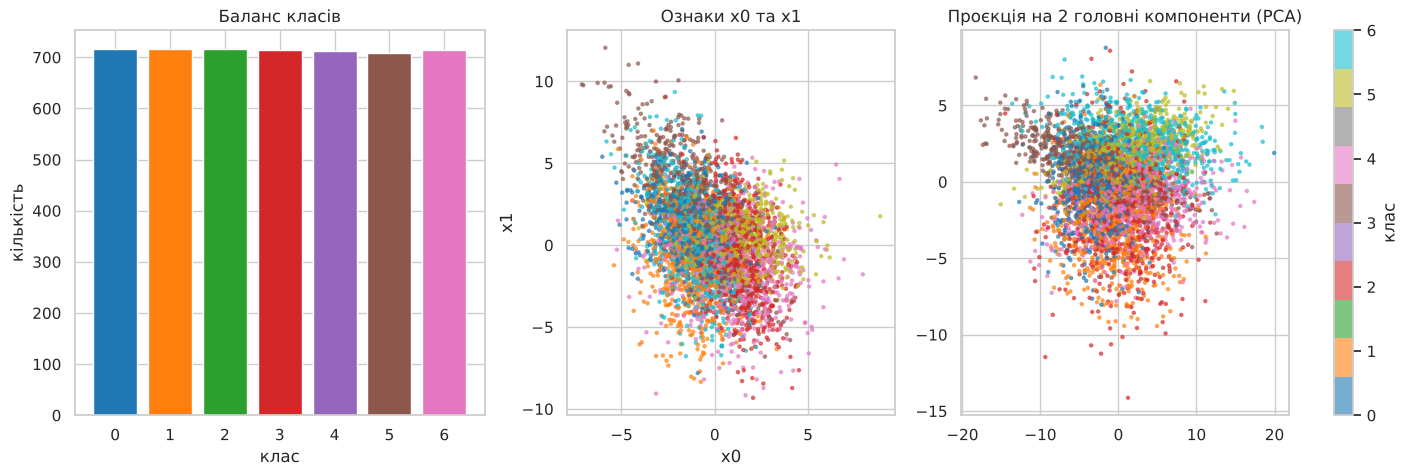

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(range(N_CLASSES), np.bincount(y_clf), color=sns.color_palette("tab10", N_CLASSES))
axes[0].set_title("Баланс класів"); axes[0].set_xlabel("клас"); axes[0].set_ylabel("кількість")

sc = axes[1].scatter(X_clf[:, 0], X_clf[:, 1], c=y_clf, cmap="tab10", s=5, alpha=0.6)
axes[1].set_title("Ознаки x0 та x1"); axes[1].set_xlabel("x0"); axes[1].set_ylabel("x1")

X_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_clf)
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=y_clf, cmap="tab10", s=5, alpha=0.6)
axes[2].set_title("Проєкція на 2 головні компоненти (PCA)")
plt.colorbar(sc, ax=axes[1:], label="клас")
plt.show()

Класи збалансовані (~714 об'єктів на клас). У двовимірних проєкціях класи сильно перекриваються — розділити їх можна лише використовуючи всі 12 вимірів, тож задача нетривіальна.

## 2. Побудова та навчання моделей
### 2.1. Підготовка: розподіл train / test та масштабування
Ділимо дані 80/20; з тренувальної частини Keras додатково відокремлює 20% на валідацію (`validation_split`). `StandardScaler` навчаємо тільки на train. Для регресії масштабуємо і ціль `y`, щоб пришвидшити навчання, а MSE рахуємо в початкових одиницях.

In [6]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)
sx_r, sy_r = StandardScaler().fit(Xr_train), StandardScaler().fit(yr_train.reshape(-1, 1))
Xr_train_s, Xr_test_s = sx_r.transform(Xr_train), sx_r.transform(Xr_test)
yr_train_s = sy_r.transform(yr_train.reshape(-1, 1)).ravel()

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clf, y_clf, test_size=0.2,
                                                        random_state=RANDOM_STATE, stratify=y_clf)
sx_c = StandardScaler().fit(Xc_train)
Xc_train_s, Xc_test_s = sx_c.transform(Xc_train), sx_c.transform(Xc_test)

print("Регресія  — train:", Xr_train.shape, "test:", Xr_test.shape)
print("Класифікація — train:", Xc_train.shape, "test:", Xc_test.shape)

Регресія  — train: (4000, 6) test: (1000, 6)
Класифікація — train: (4000, 12) test: (1000, 12)


### 2.2. Нейронна мережа для регресії
Архітектура: `6 → Dense(64, ReLU) → Dense(64, ReLU) → Dense(32, ReLU) → Dense(1)` (лінійний вихід).
- Функція втрат — **MSE**, оптимізатор — **Adam**.
- `EarlyStopping` зупиняє навчання, коли помилка на валідації перестає зменшуватись, і повертає найкращі ваги — захист від перенавчання.

In [7]:
def build_regressor(n_features):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1),
    ], name="regressor")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return model

model_reg = build_regressor(Xr_train_s.shape[1])
model_reg.summary()

early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
hist_reg = model_reg.fit(Xr_train_s, yr_train_s, validation_split=0.2, epochs=300, batch_size=32,
                         callbacks=[early], verbose=0)
print("Навчання завершено на епосі", len(hist_reg.history["loss"]))

Model: "regressor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,721 (26.25 KB)

 Trainable params: 6,721 (26.25 KB)

 Non-trainable params: 0 (0.00 B)

Навчання завершено на епосі 63


### 2.3. Нейронна мережа для класифікації
Архітектура: `12 → Dense(128, ReLU) → Dropout(0.2) → Dense(64, ReLU) → Dropout(0.2) → Dense(7, Softmax)`.
- Вихідний шар має **7 нейронів** (за кількістю класів) з softmax — отримуємо ймовірності кожного класу.
- Функція втрат — `sparse_categorical_crossentropy` (мітки — цілі числа 0…6), метрика — accuracy.
- `Dropout` випадково «вимикає» 20% нейронів під час навчання — регуляризація.

In [8]:
def build_classifier(n_features, n_classes):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(n_classes, activation="softmax"),
    ], name="classifier")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model_clf = build_classifier(Xc_train_s.shape[1], N_CLASSES)
model_clf.summary()

early_c = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
hist_clf = model_clf.fit(Xc_train_s, yc_train, validation_split=0.2, epochs=300, batch_size=32,
                         callbacks=[early_c], verbose=0)
print("Навчання завершено на епосі", len(hist_clf.history["loss"]))

Model: "classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,375 (40.53 KB)

 Trainable params: 10,375 (40.53 KB)

 Non-trainable params: 0 (0.00 B)

Навчання завершено на епосі 54


## 3. Оцінка моделей
### 3.1. Регресія: Mean Squared Error
Для порівняння навчимо також звичайну лінійну регресію (baseline).

In [9]:
yr_pred = sy_r.inverse_transform(model_reg.predict(Xr_test_s, verbose=0)).ravel()
lin = LinearRegression().fit(Xr_train_s, yr_train)
yr_pred_lin = lin.predict(Xr_test_s)

reg_table = pd.DataFrame({
    "MSE": [mean_squared_error(yr_test, yr_pred), mean_squared_error(yr_test, yr_pred_lin)],
    "RMSE": [np.sqrt(mean_squared_error(yr_test, yr_pred)), np.sqrt(mean_squared_error(yr_test, yr_pred_lin))],
    "MAE": [mean_absolute_error(yr_test, yr_pred), mean_absolute_error(yr_test, yr_pred_lin)],
    "R²": [r2_score(yr_test, yr_pred), r2_score(yr_test, yr_pred_lin)],
}, index=["Нейронна мережа (Keras)", "Лінійна регресія (baseline)"]).round(3)
print("Дисперсія шуму в даних = 10² = 100 (нижня межа досяжної MSE)")
reg_table

Дисперсія шуму в даних = 10² = 100 (нижня межа досяжної MSE)


,MSE,RMSE,MAE,R²
Нейронна мережа (Keras),242.183,15.562,11.598,0.988
Лінійна регресія (baseline),1889.790,43.472,32.357,0.904


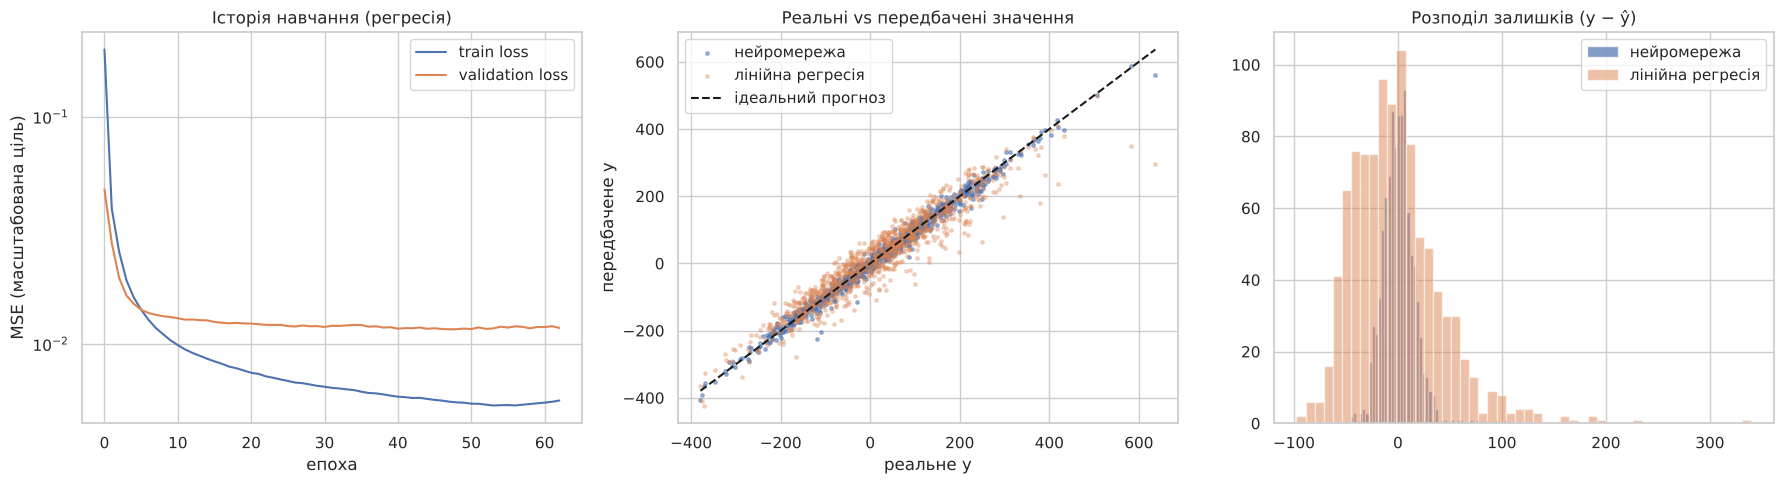

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(hist_reg.history["loss"], label="train loss")
axes[0].plot(hist_reg.history["val_loss"], label="validation loss")
axes[0].set_yscale("log"); axes[0].set_xlabel("епоха"); axes[0].set_ylabel("MSE (масштабована ціль)")
axes[0].set_title("Історія навчання (регресія)"); axes[0].legend()

lims = [yr_test.min(), yr_test.max()]
axes[1].scatter(yr_test, yr_pred, s=6, alpha=0.5, label="нейромережа")
axes[1].scatter(yr_test, yr_pred_lin, s=6, alpha=0.3, label="лінійна регресія")
axes[1].plot(lims, lims, "k--", label="ідеальний прогноз")
axes[1].set_xlabel("реальне y"); axes[1].set_ylabel("передбачене y")
axes[1].set_title("Реальні vs передбачені значення"); axes[1].legend()

axes[2].hist(yr_test - yr_pred, bins=50, alpha=0.7, label="нейромережа")
axes[2].hist(yr_test - yr_pred_lin, bins=50, alpha=0.5, label="лінійна регресія")
axes[2].set_title("Розподіл залишків (y − ŷ)"); axes[2].legend()
plt.tight_layout(); plt.show()

### 3.2. Класифікація: Accuracy та матриця плутанини

In [11]:
proba = model_clf.predict(Xc_test_s, verbose=0)
yc_pred = proba.argmax(axis=1)
acc_nn = accuracy_score(yc_test, yc_pred)
acc_lr = accuracy_score(yc_test, LogisticRegression(max_iter=2000).fit(Xc_train_s, yc_train).predict(Xc_test_s))
train_acc = accuracy_score(yc_train, model_clf.predict(Xc_train_s, verbose=0).argmax(axis=1))

print(f"Accuracy нейромережі на тесті:   {acc_nn:.4f}")
print(f"Accuracy нейромережі на train:   {train_acc:.4f}")
print(f"Accuracy логістичної регресії:   {acc_lr:.4f}  (baseline)")
print(f"Випадкове вгадування (1/7):      {1/N_CLASSES:.4f}\n")
print(classification_report(yc_test, yc_pred, digits=3))

Accuracy нейромережі на тесті:   0.9590
Accuracy нейромережі на train:   0.9752
Accuracy логістичної регресії:   0.7940  (baseline)
Випадкове вгадування (1/7):      0.1429

              precision    recall  f1-score   support

           0      0.950     0.923     0.936       143
           1      0.964     0.937     0.950       143
           2      0.914     0.972     0.942       143
           3      0.959     0.986     0.972       143
           4      0.986     0.979     0.982       143
           5      0.993     0.958     0.975       142
           6      0.951     0.958     0.955       143

    accuracy                          0.959      1000
   macro avg      0.960     0.959     0.959      1000
weighted avg      0.960     0.959     0.959      1000



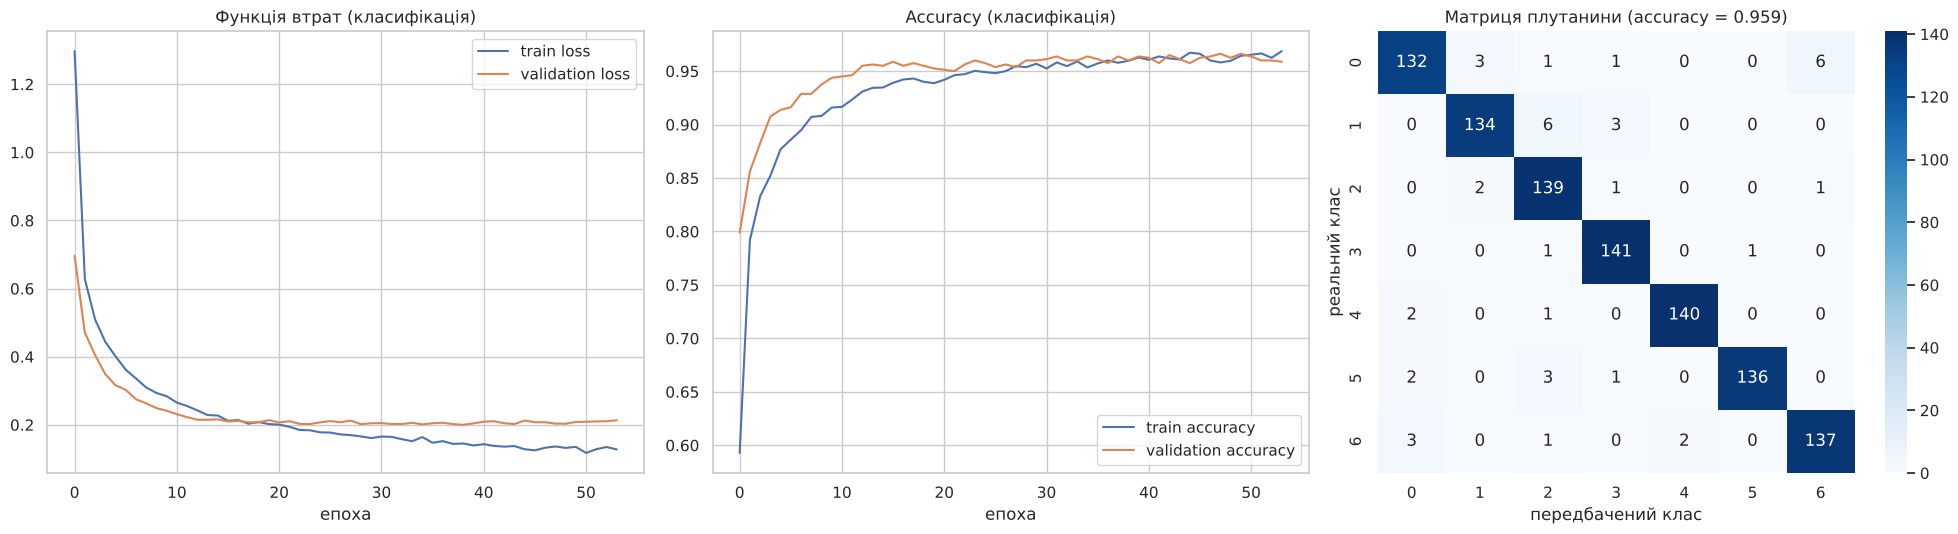

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].plot(hist_clf.history["loss"], label="train loss")
axes[0].plot(hist_clf.history["val_loss"], label="validation loss")
axes[0].set_xlabel("епоха"); axes[0].set_title("Функція втрат (класифікація)"); axes[0].legend()

axes[1].plot(hist_clf.history["accuracy"], label="train accuracy")
axes[1].plot(hist_clf.history["val_accuracy"], label="validation accuracy")
axes[1].set_xlabel("епоха"); axes[1].set_title("Accuracy (класифікація)"); axes[1].legend()

cm = confusion_matrix(yc_test, yc_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[2])
axes[2].set_title(f"Матриця плутанини (accuracy = {acc_nn:.3f})")
axes[2].set_xlabel("передбачений клас"); axes[2].set_ylabel("реальний клас")
plt.tight_layout(); plt.show()

In [13]:
# Які класи модель плутає найчастіше
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], i, j) for i in range(N_CLASSES) for j in range(N_CLASSES) if off[i, j]), reverse=True)[:5]
for n, i, j in pairs:
    print(f"клас {i} → прогнозовано як {j}: {n} разів")
print("\nRecall по класах:", np.round(cm.diagonal() / cm.sum(axis=1), 3))

клас 1 → прогнозовано як 2: 6 разів
клас 0 → прогнозовано як 6: 6 разів
клас 6 → прогнозовано як 0: 3 разів
клас 5 → прогнозовано як 2: 3 разів
клас 1 → прогнозовано як 3: 3 разів

Recall по класах: [0.923 0.937 0.972 0.986 0.979 0.958 0.958]


## 4. Висновки
Числові значення нижче підставляються з результатів виконання ноутбука.

In [14]:
print(f"""РЕГРЕСІЯ ({N_SAMPLES} зразків, 6 ознак):
  MSE нейромережі = {reg_table.iloc[0]['MSE']:.1f}, R² = {reg_table.iloc[0]['R²']:.3f}
  MSE лінійної регресії = {reg_table.iloc[1]['MSE']:.1f}, R² = {reg_table.iloc[1]['R²']:.3f}
  Нейромережа зменшила MSE у {reg_table.iloc[1]['MSE'] / reg_table.iloc[0]['MSE']:.1f} раза.

КЛАСИФІКАЦІЯ ({N_SAMPLES} зразків, 12 ознак, {N_CLASSES} класів):
  Accuracy нейромережі = {acc_nn:.3f} (train {train_acc:.3f}); логістична регресія = {acc_lr:.3f}; випадково = {1/N_CLASSES:.3f}""")

РЕГРЕСІЯ (5000 зразків, 6 ознак):
  MSE нейромережі = 242.2, R² = 0.988
  MSE лінійної регресії = 1889.8, R² = 0.904
  Нейромережа зменшила MSE у 7.8 раза.

КЛАСИФІКАЦІЯ (5000 зразків, 12 ознак, 7 класів):
  Accuracy нейромережі = 0.959 (train 0.975); логістична регресія = 0.794; випадково = 0.143


**Регресія.**
- Нейронна мережа з трьома прихованими шарами добре апроксимує залежність, яка містить і лінійні, і нелінійні (квадратичну, синусоїдальну) компоненти: точки на графіку «реальні vs передбачені» щільно лежать біля діагоналі, R² близький до 1.
- Лінійна регресія не може відтворити нелінійну частину, тому її MSE у кілька разів більша, а залишки мають зміщений розподіл. Це показує головну перевагу нейромереж — здатність навчатися нелінійних залежностей без ручного конструювання ознак.
- Нижня межа досяжної MSE — дисперсія шуму (100). MSE нейромережі (~240) лише в ~2.4 раза вища за неї, тоді як у лінійної регресії (~1890) — майже у 19 разів: мережа вивчила більшу частину «детермінованої» залежності, залишкова помилка пов'язана з неідеальним наближенням нелінійних компонент.

**Класифікація.**
- Мережа впевнено розрізняє 7 класів: accuracy значно вища за випадкове вгадування (14%) і за лінійний baseline (логістична регресія: ~0.79 проти ~0.96), оскільки класи в 12-вимірному просторі розділяються нелінійними межами.
- Криві train/validation йдуть близько одна до одної, а accuracy на train і test відрізняються мало — Dropout та EarlyStopping стримали перенавчання.
- Помилки на матриці плутанини зосереджені в кількох парах класів, кластери яких у просторі ознак розташовані поруч; для таких класів recall нижчий.

**Загалом:** масштабування ознак, відокремлена валідація, EarlyStopping і порівняння з простим baseline — обов'язкові елементи коректної роботи з нейромережами. Подальше покращення можливе через підбір архітектури (кількість шарів/нейронів), learning rate та регуляризації, а для класифікації — збільшення обсягу даних.